<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/notebooks/05_Milestone_A_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SQLSmith — Notebook 05 | Milestone A Evaluation Report

**CPU-only reporting notebook** • Qwen2.5-Coder-1.5B vs 7B • Spider 1.0 development **first 50 questions**

Reads the existing immutable 1.5B/7B summary reports, predictions and diagnostic outputs from Google Drive. Produces charts, comparison tables, a Markdown research report, and a machine-readable summary. **No LLM inference is performed.**

**Scientific guardrails:** official test-suite **subset** scores are 42% and 68%; these are not full Spider scores. Paired statistical inference requires **per-question official test-suite outcomes**, which summary JSON files alone do not provide. The notebook does not invent per-question official outcomes or infer significance from unmatched aggregate proportions.

## 1. Setup (CPU runtime)

In [1]:
%pip install -q pandas numpy matplotlib

In [2]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import json, hashlib, math, platform
from datetime import datetime, timezone
import matplotlib.pyplot as plt

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/Prajwal/Projects/SQLSmith')
RESULTS = ROOT / 'results'
OUT = ROOT / 'reports' / 'milestone_A'
OUT.mkdir(parents=True, exist_ok=True)

REPORT_1B = RESULTS / 'spider_1_5b_official_subset_evaluation.json'
REPORT_7B = RESULTS / 'spider_7b_official_subset_evaluation.json'
CSV_1B = RESULTS / 'spider_1_5b_baseline_50.csv'
CSV_7B = RESULTS / 'spider_7b_baseline_50.csv'
for f in [REPORT_1B,REPORT_7B,CSV_1B,CSV_7B]:
    assert f.is_file(), f'Missing input: {f}'
print('Input files found. Report destination:', OUT)


Mounted at /content/drive
Input files found. Report destination: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/reports/milestone_A


## 2. Load official metadata and validate matching evaluation settings

In [3]:
one = json.loads(REPORT_1B.read_text(encoding='utf-8'))
seven = json.loads(REPORT_7B.read_text(encoding='utf-8'))

def sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

assert int(one['sample_size']) == int(seven['sample_size']) == 50
assert one['evaluator_commit'] == seven['evaluator_commit'], 'Evaluator commits differ'
assert one['gold_file_sha256'] == seven['gold_file_sha256'], 'Gold SQL hashes differ'
assert one['test_suite_archive_sha256'] == seven['test_suite_archive_sha256'], 'Test suite archives differ'
assert one['plug_value'] is False and seven['plug_value'] is False
assert one['keep_distinct'] is False and seven['keep_distinct'] is False
assert one['full_dev_evaluated'] is False and seven['full_dev_evaluated'] is False
assert sha(CSV_1B) == one['baseline_source_sha256'], 'Original 1.5B source file differs from 03 report'
assert sha(CSV_1B) == seven['source_1b_sha256'], '7B report points to a different 1.5B source'
assert sha(CSV_7B) == seven['predictions_csv_sha256'], '7B predictions CSV changed'

acc_1 = float(one['official_subset_accuracy'])
acc_7 = float(seven['official_subset_accuracy'])
assert 0 <= acc_1 <= 1 and 0 <= acc_7 <= 1
n = 50
num_1 = round(acc_1*n); num_7 = round(acc_7*n)
assert abs(num_1/n-acc_1) < 1e-9 and abs(num_7/n-acc_7) < 1e-9
print(f'Official subset accuracy: 1.5B {num_1}/{n} ({acc_1:.1%}), 7B {num_7}/{n} ({acc_7:.1%})')
print('Difference:', round((acc_7-acc_1)*100,1),'percentage points')
print('Evaluator commit:',one['evaluator_commit'])
print('Gold SHA256:',one['gold_file_sha256'])


Official subset accuracy: 1.5B 21/50 (42.0%), 7B 34/50 (68.0%)
Difference: 26.0 percentage points
Evaluator commit: e97acc546ecbee8fa27fa8dbf025ef61493a876c
Gold SHA256: 2523871ac4fa312076a17448302d1778c254e5b072bb0e3cc509dd79e7eeb930


## 3. Validate the predictions refer to the same 50 questions

In [4]:
df1 = pd.read_csv(CSV_1B, keep_default_na=False)
df7 = pd.read_csv(CSV_7B, keep_default_na=False)
for name,d in [('1.5B',df1),('7B',df7)]:
    required={'index','db_id','question','gold_sql','predicted_sql'}
    assert required.issubset(d.columns),f'{name} missing {required-set(d.columns)}'
    d['index']=pd.to_numeric(d['index'], errors='raise').astype(int)
    assert d['index'].is_unique and sorted(d['index']) == list(range(1,51)), f'{name} has unexpected IDs'

def collapse(s): return ' '.join(str(s).split())
aligned=df1[['index','db_id','question','gold_sql']].merge(
    df7[['index','db_id','question','gold_sql']],on='index',suffixes=('_1b','_7b'),validate='one_to_one')
for field in ['db_id','question','gold_sql']:
    assert all(aligned[f'{field}_1b'].map(collapse)==aligned[f'{field}_7b'].map(collapse)), f'{field} differs'
assert (df7['predicted_sql'].astype(str).str.strip() != '').all(), 'Empty 7B predictions found'
print('PASS: Same 50 question IDs, database IDs, natural-language questions and gold SQL.')
print('Databases:',df1['db_id'].value_counts().to_dict())


PASS: Same 50 question IDs, database IDs, natural-language questions and gold SQL.
Databases: {'concert_singer': 45, 'pets_1': 5}


## 4. Accuracy chart and descriptive uncertainty

Wilson intervals below are **marginal descriptive 95% intervals** for each model’s proportion on 50 questions. They **do not** establish the statistical significance of the paired model difference; furthermore, the first-50 subset is not a random cross-domain sample.

,model,correct,total,official_subset_accuracy_pct,wilson_95_low_pct,wilson_95_high_pct
0,Qwen 1.5B,21,50,42.0,29.38,55.77
1,Qwen 7B,34,50,68.0,54.19,79.24


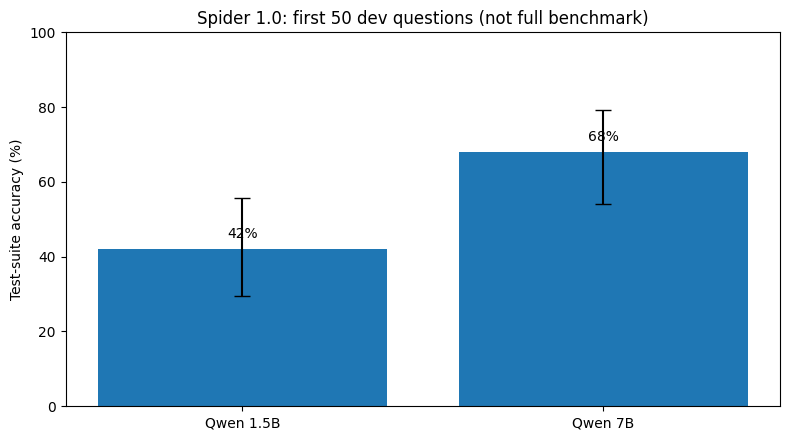

In [5]:
from statistics import NormalDist

def wilson(k,n,z=1.959963984540054):
    p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return center-half, center+half

rows=[]
for model,k in [('Qwen 1.5B',num_1),('Qwen 7B',num_7)]:
    lo,hi=wilson(k,n)
    rows.append({'model':model,'correct':k,'total':n,'official_subset_accuracy_pct':100*k/n,
                 'wilson_95_low_pct':100*lo,'wilson_95_high_pct':100*hi})
accuracy_df=pd.DataFrame(rows)
display(accuracy_df.round(2))
fig,ax=plt.subplots(figsize=(8,4.5))
vals=accuracy_df['official_subset_accuracy_pct'].to_numpy()
lo=vals-accuracy_df['wilson_95_low_pct'].to_numpy()
hi=accuracy_df['wilson_95_high_pct'].to_numpy()-vals
ax.bar(accuracy_df['model'],vals,yerr=[lo,hi],capsize=6)
ax.set_ylim(0,100);ax.set_ylabel('Test-suite accuracy (%)')
ax.set_title('Spider 1.0: first 50 dev questions (not full benchmark)')
for i,v in enumerate(vals):ax.text(i,v+3,f'{v:.0f}%',ha='center')
fig.tight_layout();fig.savefig(OUT/'official_accuracy_comparison.png',dpi=180);plt.show()
accuracy_df.to_csv(OUT/'accuracy_summary.csv',index=False)


## 5. Difficulty breakdown (with limits)

The source reports provide accuracy by difficulty but not necessarily the number of questions per category. **Never interpret an extra-hard percentage without its denominator.**

,difficulty,qwen_1_5b_pct,qwen_7b_pct,delta_pp
0,easy,66.7,100.0,33.3
1,medium,40.7,63.0,22.3
2,hard,30.8,76.9,46.1
3,extra,50.0,25.0,-25.0


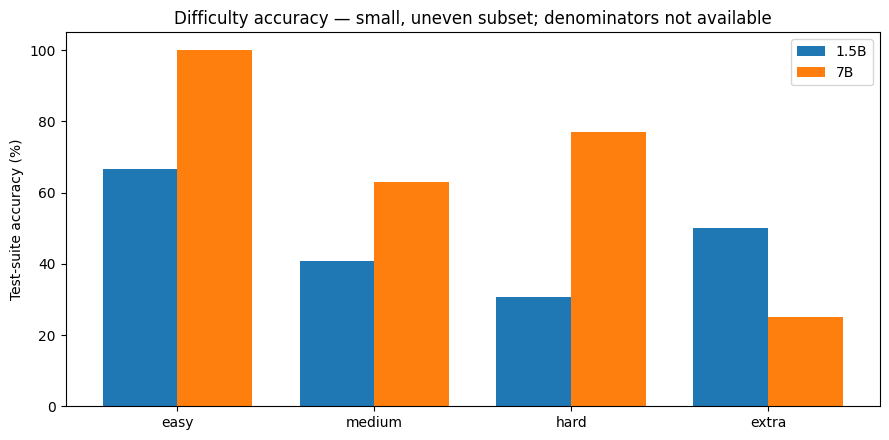

In [6]:
levels=['easy','medium','hard','extra']
difficulty_df=pd.DataFrame({
    'difficulty':levels,
    'qwen_1_5b_pct':[100*float(one['scores_by_difficulty'][x]) for x in levels],
    'qwen_7b_pct':[100*float(seven['scores_by_difficulty'][x]) for x in levels],
})
difficulty_df['delta_pp']=difficulty_df['qwen_7b_pct']-difficulty_df['qwen_1_5b_pct']
display(difficulty_df.round(1))
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(len(levels));w=.38
ax.bar(x-w/2,difficulty_df['qwen_1_5b_pct'],w,label='1.5B')
ax.bar(x+w/2,difficulty_df['qwen_7b_pct'],w,label='7B')
ax.set_xticks(x,levels);ax.set_ylim(0,105);ax.set_ylabel('Test-suite accuracy (%)')
ax.set_title('Difficulty accuracy — small, uneven subset; denominators not available')
ax.legend();fig.tight_layout();fig.savefig(OUT/'accuracy_by_difficulty.png',dpi=180);plt.show()
difficulty_df.to_csv(OUT/'difficulty_summary.csv',index=False)


## 6. Latency and memory

The 1.5B mean was measured in Notebook 01; the 7B mean/p95 were measured in Notebook 04. Generation conditions may differ, so their latency figures are **descriptive**, not a controlled claim that 7B is faster. GPU allocated memory is not total board use.

,model,n,mean_sec,median_sec,p95_sec,std_sec
0,Qwen 1.5B,50,3.629,3.045,9.444,2.810
1,Qwen 7B,50,1.957,1.377,4.088,1.257


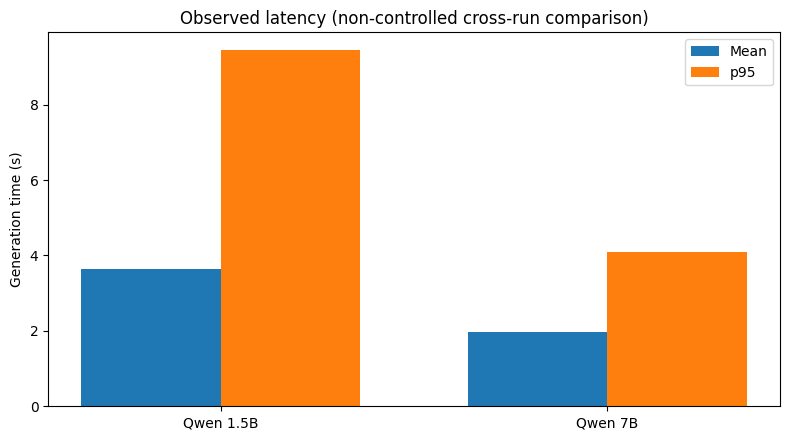

7B tokens/sec (reported): 14.281956510974826
7B peak torch allocated GiB (reported): 6.584


In [7]:
lat_1b=pd.to_numeric(df1.get('latency_seconds',pd.Series(dtype=float)),errors='coerce').dropna()
lat_7b=pd.to_numeric(df7.get('latency_seconds',pd.Series(dtype=float)),errors='coerce').dropna()
assert len(lat_1b)==50 and len(lat_7b)==50, 'Need all 50 latencies for each model'
latency_df=pd.DataFrame([
    {'model':'Qwen 1.5B','n':len(lat_1b),'mean_sec':lat_1b.mean(),'median_sec':lat_1b.median(),'p95_sec':lat_1b.quantile(.95),'std_sec':lat_1b.std()},
    {'model':'Qwen 7B','n':len(lat_7b),'mean_sec':lat_7b.mean(),'median_sec':lat_7b.median(),'p95_sec':lat_7b.quantile(.95),'std_sec':lat_7b.std()},
])
assert abs(lat_7b.mean()-seven['mean_generation_latency_seconds'])<0.02, '7B latency inconsistent with report'
display(latency_df.round(3))
fig,ax=plt.subplots(figsize=(8,4.5));x=np.arange(2);w=.36
ax.bar(x-w/2,latency_df['mean_sec'],w,label='Mean')
ax.bar(x+w/2,latency_df['p95_sec'],w,label='p95')
ax.set_xticks(x,latency_df['model']);ax.set_ylabel('Generation time (s)');ax.set_title('Observed latency (non-controlled cross-run comparison)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'latency_comparison.png',dpi=180);plt.show()
latency_df.to_csv(OUT/'latency_summary.csv',index=False)
print('7B tokens/sec (reported):',seven.get('mean_generated_tokens_per_second'))
print('7B peak torch allocated GiB (reported):',seven.get('peak_gpu_memory_allocated_gib'))


## 7. Failure analysis (from Notebook 02, if saved)

In [8]:
review_path=RESULTS/'spider_1_5b_consolidated_review_final.csv'
review_summary=None
if review_path.exists():
    reviewed=pd.read_csv(review_path)
    print('Loaded reviewed failure cases:',len(reviewed))
    print('Initial categories:')
    display(reviewed['initial_error_category'].value_counts().rename_axis('category').reset_index(name='count'))
    if 'root_cause' in reviewed.columns:
        print('Reviewed cause labels (descriptive, not necessarily validated):')
        display(reviewed['root_cause'].fillna('Unclassified').value_counts().rename_axis('cause').reset_index(name='count'))
    review_summary=reviewed['initial_error_category'].value_counts().to_dict()
else:
    print('Optional Notebook 02 consolidated CSV not found; skipping chart. No error counts invented.')


Loaded reviewed failure cases: 26
Initial categories:


,category,count
0,Invalid column,12
1,Semantic mismatch - review required,9
2,Query validation rejection,5


Reviewed cause labels (descriptive, not necessarily validated):


,cause,count
0,Confirmed SQLite column-resolution failure,12
1,Validator rejection; replay result mismatch,3
2,Wrong table selection,2
3,Validator rejection; replay result matches,2
4,Unnecessary join,1
5,Incorrect aggregation due to join,1
6,Column-order mismatch,1
7,Incorrect join relationship,1
8,Wrong aggregation interpretation,1
9,Wrong semantic grounding,1


## 8. Paired comparison requirement

A paired test such as McNemar’s test or paired bootstrap needs **50 official correct/incorrect flags for each model**, aligned by question ID. The model summaries, raw SQL predictions, and original 1.5B *provisional* `correct` column are not substitutes for these official flags. **We therefore do not report a p-value or confidence interval for the 26-percentage-point difference.**

In [9]:
paired_eligible=False
for key in ['official_question_scores.csv','official_per_question_scores.csv']:
    optional=RESULTS/key
    if optional.exists():
        print('Potential per-question file found (not automatically trusted):',optional)
print('Paired significance analysis: NOT PERFORMED — verified per-question official outcomes unavailable.')
print('Descriptive difference:',round((acc_7-acc_1)*100,1),'percentage points')


Paired significance analysis: NOT PERFORMED — verified per-question official outcomes unavailable.
Descriptive difference: 26.0 percentage points


## 9. Export final Markdown report and machine-readable manifest

In [10]:
now=datetime.now(timezone.utc).isoformat()
uncertainty_lines=[]
for _,r in accuracy_df.iterrows():
    uncertainty_lines.append(f"- {r['model']}: {r['correct']}/{r['total']} = {r['official_subset_accuracy_pct']:.1f}% (marginal Wilson 95% interval {r['wilson_95_low_pct']:.1f}–{r['wilson_95_high_pct']:.1f}%).")
report_md=f"""# SQLSmith — Milestone A Research Report

Generated UTC: {now}

## Research question
Can a locally runnable open-weight code model generate accurate enterprise-style SQL while maintaining private inference capability?

## Scope
Spider 1.0 **first 50 development questions**, covering {df1['db_id'].nunique()} databases ({', '.join(sorted(df1['db_id'].unique()))}). Qwen2.5-Coder-1.5B-Instruct vs Qwen2.5-Coder-7B-Instruct, baseline (no fine-tuning).

## Primary findings
- Official test-suite execution accuracy: **1.5B {num_1}/{n} ({acc_1:.1%}); 7B {num_7}/{n} ({acc_7:.1%})**.
- Descriptive improvement: **{(acc_7-acc_1)*100:.1f} percentage points** on this subset.
- 7B generation: mean {lat_7b.mean():.3f} s; p95 {lat_7b.quantile(.95):.3f} s; reported throughput {seven.get('mean_generated_tokens_per_second',float('nan')):.2f} tokens/s; peak PyTorch allocated GPU memory {seven.get('peak_gpu_memory_allocated_gib',float('nan')):.3f} GiB.
- 1.5B mean generation latency: {lat_1b.mean():.3f} s. These timings come from different sessions and cannot establish comparative speed.

## Uncertainty and validity
{chr(10).join(uncertainty_lines)}

This is a small, nonrandom, two-database subset; uncertainty intervals are descriptive only. No paired significance test is reported without per-question **official** correctness. The full Spider development set and BIRD are not evaluated. Test-suite accuracy does not establish production safety or GPT-class parity.

## Earlier diagnostic scores
The 1.5B original result matching was 48%, and diagnostic replay was 52%; these are distinct from official test-suite accuracy of 42%. They must not be mixed in model comparisons.

## Error-analysis hypotheses
Notebook 02 identified column-resolution errors, unnecessary/wrong joins, query-validation rejections, and potential reference/evaluator ambiguities. These motivate schema grounding, constrained execution and official scorer validation; they are not proof of causal improvements.

## Reproducibility
- Evaluator repository: {one.get('evaluator_repo','https://github.com/taoyds/test-suite-sql-eval')}
- Evaluator commit: `{one['evaluator_commit']}`
- Gold SQL SHA256: `{one['gold_file_sha256']}`
- Test-suite archive SHA256: `{one['test_suite_archive_sha256']}`
- 1.5B source predictions SHA256: `{sha(CSV_1B)}`
- 7B predictions CSV SHA256: `{sha(CSV_7B)}`
- `plug_value=false`, `keep_distinct=false`.

## Recommended next work
1. Freeze the end-to-end evaluation protocol and collect the **full Spider dev predictions** for both models.
2. Export official per-question pass/fail flags for paired statistical analysis.
3. Add BIRD with compatible evaluation and separate reporting.
4. Only then proceed to SFT/QLoRA and schema-linking ablations without tuning against evaluation examples.
5. Separately evaluate SQL authorization, read-only access controls, abstention, query limits and deployment cost on controlled local hardware.
"""
report_path=OUT/'Milestone_A_Report.md'
report_path.write_text(report_md,encoding='utf-8')
manifest={
 'project':'SQLSmith','milestone':'A','generated_at_utc':now,'subset':'Spider 1.0 dev first 50',
 'n':n,'database_ids':sorted(df1['db_id'].unique()),
 'model_scores':{'1.5B':acc_1,'7B':acc_7,'difference_percentage_points':(acc_7-acc_1)*100},
 'paired_inference_performed':False,'full_dev_evaluated':False,'evaluator_commit':one['evaluator_commit'],
 'gold_file_sha256':one['gold_file_sha256'],'archive_sha256':one['test_suite_archive_sha256'],
 'source_sha256':{'1.5B':sha(CSV_1B),'7B':sha(CSV_7B)},
 'artifacts':['Milestone_A_Report.md','accuracy_summary.csv','difficulty_summary.csv','latency_summary.csv','official_accuracy_comparison.png','accuracy_by_difficulty.png','latency_comparison.png']
}
manifest_path=OUT/'Milestone_A_Manifest.json'
manifest_path.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved:',report_path);print('Saved:',manifest_path)


Saved: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/reports/milestone_A/Milestone_A_Report.md
Saved: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/reports/milestone_A/Milestone_A_Manifest.json


## 10. Verify deliverables and create a shareable ZIP

In [11]:
import zipfile
required=[OUT/x for x in ['Milestone_A_Report.md','Milestone_A_Manifest.json','accuracy_summary.csv',
 'difficulty_summary.csv','latency_summary.csv','official_accuracy_comparison.png','accuracy_by_difficulty.png','latency_comparison.png']]
for f in required:
    assert f.exists() and f.stat().st_size>0,f'Missing or empty: {f}'
    print('PASS',f.name)
zip_path=OUT/'SQLSmith_Milestone_A_Report_Artifacts.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as archive:
    for f in required: archive.write(f,arcname=f.name)
print('\nAll artifacts saved:',OUT)
print('ZIP:',zip_path)
print('Commit notebook to: notebooks/05_Milestone_A_Report.ipynb')


PASS Milestone_A_Report.md
PASS Milestone_A_Manifest.json
PASS accuracy_summary.csv
PASS difficulty_summary.csv
PASS latency_summary.csv
PASS official_accuracy_comparison.png
PASS accuracy_by_difficulty.png
PASS latency_comparison.png

All artifacts saved: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/reports/milestone_A
ZIP: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/reports/milestone_A/SQLSmith_Milestone_A_Report_Artifacts.zip
Commit notebook to: notebooks/05_Milestone_A_Report.ipynb


## Completion note

Notebook 05 closes the **initial 50-example Milestone A comparison**, *not* a full Spider/BIRD research evaluation. Commit this notebook at `notebooks/05_Milestone_A_Report.ipynb` after execution. Suggested message: `docs: add reproducible Milestone A baseline report`.
